## Taller 1 Colab - Cristian David Chalaca Salas - 19/OCT

In [20]:
import numpy as np
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

PxP 784 x 784

In [19]:
# Cargar el conjunto de datos MNIST y aplanar las imágenes de 28x28 a vectores de 784 componentes
(X, Y), _ = mnist.load_data()
X = X.reshape(-1, 28*28)
N = X.shape[0]

# Calcular el vector de medias (mu) para cada píxel sobre todo el conjunto de datos
ones = np.ones([N, 1])
mu = X.T @ ones / N

In [7]:
mu.shape

(784, 1)

In [14]:
# Centrar los datos restando la media y añadir un épsilon para evitar divisiones por cero
ep = 1e-10
X_c = X - ones @ mu.T + ep

# Calcular la matriz de covarianza (784 x 784)
Cov = (1/N) * (X_c.T @ X_c)
print(Cov.shape)

# Extraer la varianza de cada píxel (diagonal de la matriz de covarianza)
aux = np.diag(Cov)
print(aux.shape)

# Crear una matriz diagonal solo con las varianzas
Var = np.diag(aux)
print(Var.shape)

(784, 784)
(784,)
(784, 784)


In [21]:
# Calcular el denominador para la matriz de correlación usando la desviación estándar
aux1 = np.diag(Cov).reshape(-1, 1)
den = aux1 @ aux1.T
print(den.shape)

# Calcular la matriz de correlación de Pearson (R = Cov / (std_i * std_j))
R = Cov / np.sqrt(den)

(784, 784)


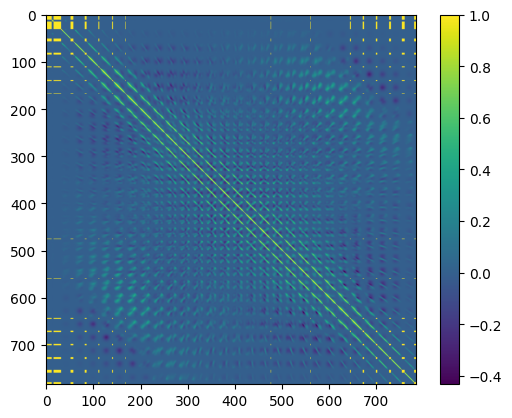

In [22]:
# Visualizar la matriz de correlación como un mapa de calor
plt.imshow(R)
plt.colorbar()
plt.show()

NxN 60.000 x 60.000 por medio de los kernels

Tamaño de la matriz de similitud de muestras: (2000, 2000)


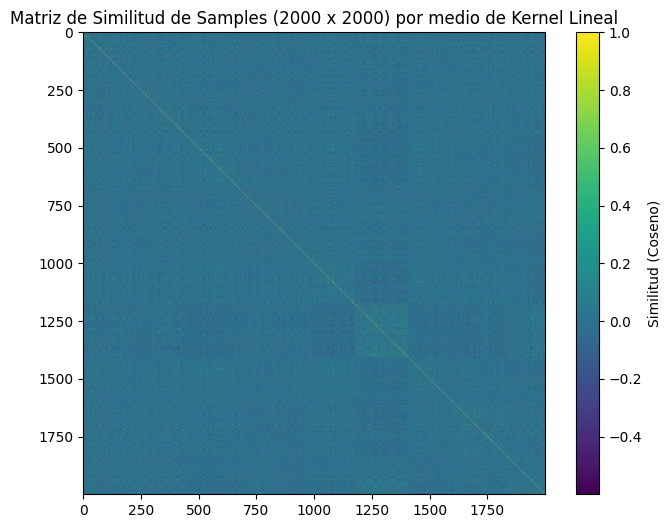

In [24]:

# Para evitar problemas de memoria (RAM), seleccionamos un subconjunto de N muestras (ej. 2000)
N_subset = 2000
X_subset = X[:N_subset].astype(float)
Y_subset = Y[:N_subset]

# 1. Centrar los datos de las muestras
# Restamos la media de cada característica para las muestras seleccionadas
X_subset_c = X_subset - np.mean(X_subset, axis=0)

# 2. Calcular la matriz del Kernel Lineal (N_subset x N_subset)
# Esto mide la similitud interna entre cada una de las imágenes (muestras)
K_lineal = X_subset_c @ X_subset_c.T

# 3. Normalizar el Kernel para obtener una matriz de correlación entre muestras (Coseno de Similitud)
diaz_K = np.diag(K_lineal).reshape(-1, 1)
den_K = np.sqrt(diaz_K @ diaz_K.T) + 1e-10
R_samples = K_lineal / den_K

print(f"Tamaño de la matriz de similitud de muestras: {R_samples.shape}")

# 4. Visualizar la matriz de similitud entre muestras
plt.figure(figsize=(8, 6))
plt.imshow(R_samples, cmap='viridis')
plt.title(f'Matriz de Similitud de Samples ({N_subset} x {N_subset}) por medio de Kernel Lineal')
plt.colorbar(label='Similitud (Coseno)')
plt.show()

### Implementación Matricial del Kernel Gaussiano y Estadísticas Asociadas

### Sustento Matemático: Estadísticas en el Espacio del Kernel Gaussiano (RBF)

Sea $X \in \mathbb{R}^{N \times P}$ la matriz que contiene los datos de entrada originales de $N$ muestras y $P$ características (píxeles).

#### 1. Matriz de Kernel Gaussiano (Gramian)
La matriz de kernel $K \in \mathbb{R}^{N \times N}$ calcula la similitud no lineal entre cada par de imágenes mediante una función de base radial (RBF):
$$K_{i,j} = \exp\left( -\gamma \|x_i - x_j\|^2 \right)$$
donde $\gamma$ es un parámetro de escala (típicamente $\gamma = \frac{1}{P}$).

#### 2. Centrado en el Espacio del Kernel
Para centrar implícitamente las características proyectadas en el espacio de Hilbert inducido por el kernel (RKHS), aplicamos la matriz de centrado simétrica $H \in \mathbb{R}^{N \times N}$ definida como:
$$H = I_N - \frac{1}{N}\mathbf{1}\mathbf{1}^T$$
donde $I_N$ es la matriz identidad de tamaño $N \times N$ y $\mathbf{1} \in \mathbb{R}^{N \times 1}$ es un vector de unos. El centrado puramente matricial se expresa como:
$$K_c = H K H = K - \frac{1}{N}\mathbf{1}\mathbf{1}^T K - K \frac{1}{N}\mathbf{1}\mathbf{1}^T + \frac{1}{N^2}\mathbf{1}\mathbf{1}^T K \mathbf{1}\mathbf{1}^T$$

#### 3. Matriz de Covarianza en el Espacio de Kernel
Una vez que la matriz de Gram está centrada, la covarianza muestral de los datos en el espacio del kernel viene dada por la escala de la muestra:
$$\text{Cov}_K = \frac{1}{N} K_c$$

#### 4. Vector de Varianzas
Las varianzas de las muestras individuales dentro del espacio inducido corresponden a los elementos diagonales de la matriz de covarianza centrada:
$$\text{Var}_K = \text{diag}(\text{Cov}_K) = \frac{1}{N} \text{diag}(K_c)$$

#### 5. Matriz de Correlación ($R_K$)
Para obtener coeficientes adimensionales de correlación, normalizamos la matriz centrada $K_c$ utilizando sus componentes de varianza mediante escalamiento simétrico:
$$R_K = D^{-1/2} K_c D^{-1/2}$$
donde $D = \text{diag}(\text{diag}(K_c))$ es una matriz diagonal que contiene los elementos diagonales de $K_c$. De manera equivalente y vectorizada:
$$(R_K)_{i,j} = \frac{(K_c)_{i,j}}{\sqrt{(K_c)_{i,i} \cdot (K_c)_{j,j}} + \epsilon}$$
donde $\epsilon > 0$ es un factor infinitesimal de estabilidad numérica.

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# 1. Definir un conjunto de muestras representativo (N_k = 3000)
# Esto asegura un cálculo matricial rápido y sin problemas de memoria RAM en Colab
N_k = 3000
X_k = X[:N_k].astype(float) / 255.0

# 2. Calcular la Matriz de Kernel Gaussiano (K) de manera vectorizada usando distancias euclidianas
gamma = 1.0 / X_k.shape[1]  # Escala de gama usual (1 / n_features)
dist_sq = cdist(X_k, X_k, metric='sqeuclidean')
K = np.exp(-gamma * dist_sq)
print(f"Dimensiones de la Matriz de Kernel K: {K.shape}")

# 3. Centrar la Matriz de Kernel utilizando algebra matricial (H * K * H)
# H es la matriz de centrado H = I - (1/N)*1*1^T
H = np.eye(N_k) - (1.0 / N_k) * np.ones((N_k, N_k))
K_c = H @ K @ H
print(f"Dimensiones de la Matriz Centrada Kc: {K_c.shape}")

# 4. Calcular la Matriz de Covarianza en el espacio del Kernel
Cov_K = (1.0 / N_k) * K_c
print(f"Dimensiones de la Matriz de Covarianza: {Cov_K.shape}")

# 5. Extraer el Vector de Varianza (Diagonal de la Matriz de Covarianza)
var_vector = np.diag(Cov_K)
print(f"Dimensiones de las Varianzas en el Kernel: {var_vector.shape}")

# 6. Calcular la Matriz de Correlación en el espacio del Kernel (R_K)
diag_Kc = np.diag(K_c).reshape(-1, 1)
# Sumamos un pequeño epsilon para garantizar estabilidad numérica
den_Kc = np.sqrt(diag_Kc @ diag_Kc.T) + 1e-12
R_K = K_c / den_Kc
print(f"Dimensiones de la Matriz de Correlación: {R_K.shape}")

Dimensiones de la Matriz de Kernel K: (3000, 3000)
Dimensiones de la Matriz Centrada Kc: (3000, 3000)
Dimensiones de la Matriz de Covarianza: (3000, 3000)
Dimensiones de las Varianzas en el Kernel: (3000,)
Dimensiones de la Matriz de Correlación: (3000, 3000)


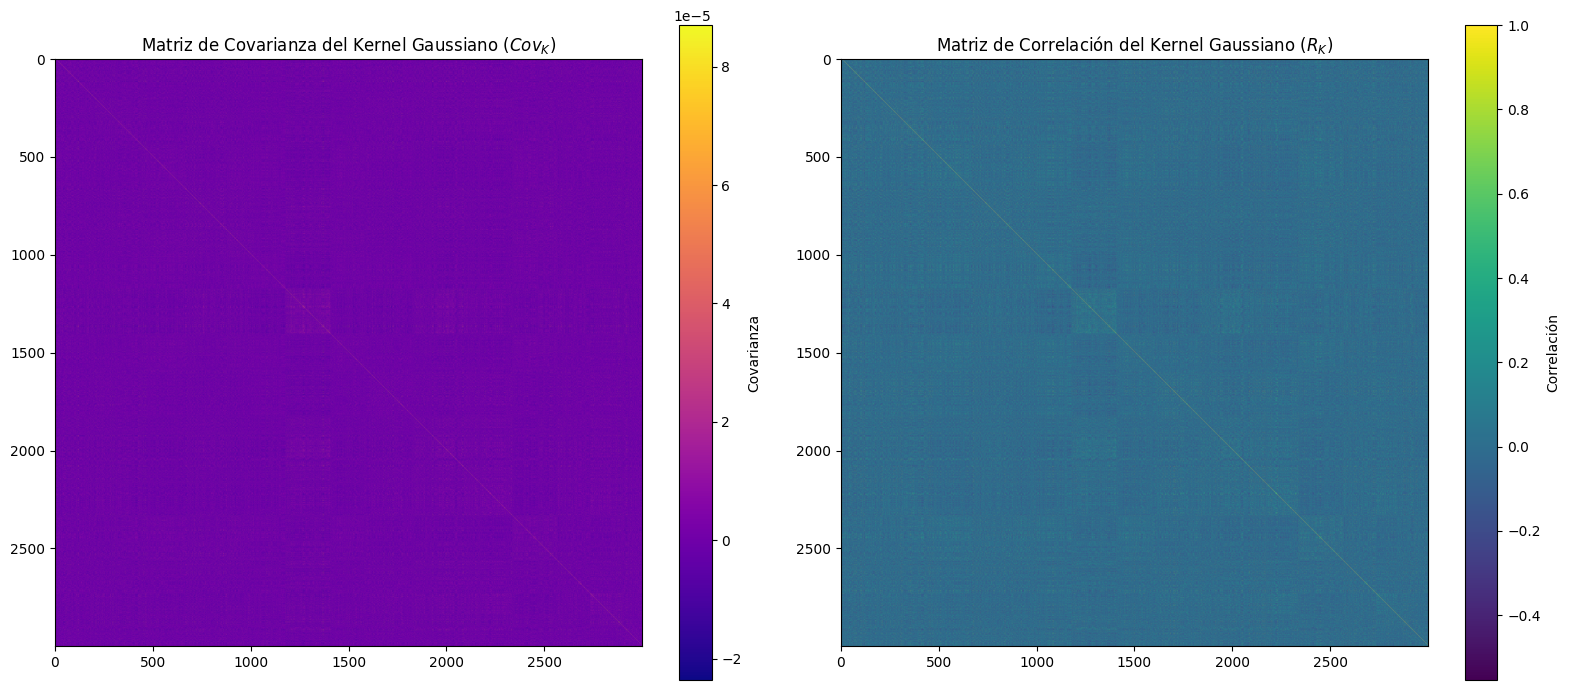

In [28]:
# 7. Graficar los resultados estadísticos obtenidos con el Kernel Gaussiano
fig, axs = plt.subplots(1, 2, figsize=(16, 7))

# Mapa de calor de la Covarianza
im1 = axs[0].imshow(Cov_K, cmap='plasma')
axs[0].set_title("Matriz de Covarianza del Kernel Gaussiano ($Cov_K$)", fontsize=12)
fig.colorbar(im1, ax=axs[0], label='Covarianza')

# Mapa de calor de la Correlación
im2 = axs[1].imshow(R_K, cmap='viridis')
axs[1].set_title("Matriz de Correlación del Kernel Gaussiano ($R_K$)", fontsize=12)
fig.colorbar(im2, ax=axs[1], label='Correlación')

plt.tight_layout()
plt.show()